# 06 — Head Localization: Learned Sparse Mask

Learn a continuous mask over `(n_layers_tested, n_heads)` attention heads that selects the minimal set whose cross-language interchange (C++ source → Python destination) minimizes `KL(P_patched ∥ P_target)`.

**Objective:**
```
L = KL(P_patched ∥ P_target) + λ * Σ mask
```
- `P_patched`: next-token dist of dest prompt with mask-weighted head patch from source (C++)
- `P_target`: next-token dist of Python target prompt (same predicate as C++ source)
- Mask: `(n_layers_tested, n_heads)` values ∈ [0,1], initialized to 1, projected GD (no sigmoid)
- Selection: heads where mask > 0.5 after training

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-03-20 16:52:36 __main__ INFO     torch.__version__='2.6.0+cu124', torch.version.cuda='12.4'
2026-03-20 16:52:38 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=4, torch.cuda.get_device_name()='NVIDIA A100-SXM4-80GB'
2026-03-20 16:52:38 __main__ INFO     transformers.__version__='5.3.0'


## Model init

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-03-20 16:52:39 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-20 16:52:39 httpx DEBUG    load_ssl_context verify=True cert=None trust_env=True http2=False
2026-03-20 16:52:39 httpx DEBUG    load_verify_locations cafile='/disk/u/arnab/miniconda3/envs/goals/lib/python3.11/site-packages/certifi/cacert.pem'
2026-03-20 16:52:39 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-20 16:52:39 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fd81d018450>
2026-03-20 16:52:39 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fd81ce117f0> server_hostname='huggingface.co' timeout=10
2026-03-20 16:52:39 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._b

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-20 16:52:56 httpcore.connection DEBUG    close.started
2026-03-20 16:52:56 httpcore.connection DEBUG    close.complete
2026-03-20 16:52:56 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-20 16:52:56 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fd81b5da390>
2026-03-20 16:52:56 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fd81ce117f0> server_hostname='huggingface.co' timeout=10
2026-03-20 16:52:56 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fd81d0fcf50>
2026-03-20 16:52:56 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-20 16:52:56 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-20 16:52:56 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load data

In [4]:
from src.goals.head_loc_data import HeadLocDataset

# Use "test" while mining is running; swap to mt.name.split("/")[-1] when done
# MODEL_NAME = "test"
MODEL_NAME = "Qwen2.5-Coder-32B-Instruct"

ds = HeadLocDataset.load(model_name=MODEL_NAME)
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]

pairs_with_pivots = [p for p in ds.pairs if p.pivot_instances]
print(f"Predicates : {len(ds.samples)}")
print(f"Pairs total: {len(ds.pairs)}")
print(f"Pairs w/ pivots: {len(pairs_with_pivots)}")
print(f"Pivot instances: {len(pivot_instances)}")

2026-03-20 16:52:59 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/Qwen2.5-Coder-32B-Instruct.json
Predicates : 21
Pairs total: 110
Pairs w/ pivots: 103
Pivot instances: 1480


In [5]:
from rich.console import Console
from rich.table import Table

console = Console(width=100, highlight=False)
table = Table(title=f"Pairs with pivot instances ({MODEL_NAME})", highlight=False)
table.add_column("Destination", style="cyan")
table.add_column("Source (C++)", style="magenta")
table.add_column("Type", style="yellow")
table.add_column("# Pivots", style="green", justify="right")

for p in ds.pairs:
    if p.pivot_instances:
        table.add_row(
            p.destination_predicate,
            p.source_predicate,
            p.variable_type,
            str(len(p.pivot_instances)),
        )

console.print(table)

       Pairs with pivot instances (Qwen2.5-Coder-32B-Instruct)       
┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┓
┃ Destination            ┃ Source (C++)           ┃ Type ┃ # Pivots ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━┩
│ all_same               │ all_even               │ list │       23 │
│ all_even               │ all_same               │ list │       23 │
│ has_duplicates         │ all_even               │ list │       11 │
│ all_even               │ has_duplicates         │ list │        9 │
│ is_sorted              │ all_even               │ list │       22 │
│ all_even               │ is_sorted              │ list │       27 │
│ is_strictly_decreasing │ all_even               │ list │       29 │
│ all_even               │ is_strictly_decreasing │ list │       29 │
│ is_strictly_sorted     │ all_even               │ list │       25 │
│ all_even               │ is_strictly_sorted     │ list │       20 │
│ all_same               │ all_positive           │ list │       26 │
│ all_positive           │ all_same               │ list │       26 │
│ has_duplicates         │ all_positive           │ list │        9 │
│ all_positive           │ has_duplicates         │ list │        9 │
│ is_sorted              │ all_positive           │ list │       18 │
│ all_positive           │ is_sorted              │ list │       19 │
│ is_strictly_decreasing │ all_positive           │ list │       13 │
│ all_positive           │ is_strictly_decreasing │ list │       13 │
│ is_strictly_sorted     │ all_positive           │ list │       22 │
│ all_positive           │ is_strictly_sorted     │ list │       25 │
│ is_sorted              │ all_same               │ list │       26 │
│ all_same               │ is_sorted              │ list │       32 │
│ is_strictly_decreasing │ all_same               │ list │       26 │
│ all_same               │ is_strictly_decreasing │ list │       20 │
│ is_strictly_sorted     │ all_same               │ list │       23 │
│ all_same               │ is_strictly_sorted     │ list │       28 │
│ is_sorted              │ has_duplicates         │ list │       17 │
│ has_duplicates         │ is_sorted              │ list │        4 │
│ is_strictly_decreasing │ has_duplicates         │ list │       13 │
│ has_duplicates         │ is_strictly_decreasing │ list │       13 │
│ is_strictly_sorted     │ has_duplicates         │ list │       17 │
│ has_duplicates         │ is_strictly_sorted     │ list │        8 │
│ has_spaces             │ ends_with_vowel        │ str  │       17 │
│ ends_with_vowel        │ has_spaces             │ str  │       12 │
│ is_digit_string        │ ends_with_vowel        │ str  │        1 │
│ ends_with_vowel        │ is_digit_string        │ str  │        9 │
│ is_lower               │ ends_with_vowel        │ str  │        5 │
│ ends_with_vowel        │ is_lower               │ str  │       16 │
│ is_palindrome          │ ends_with_vowel        │ str  │       19 │
│ ends_with_vowel        │ is_palindrome          │ str  │       10 │
│ is_upper               │ ends_with_vowel        │ str  │        8 │
│ ends_with_vowel        │ is_upper               │ str  │        5 │
│ is_digit_string        │ has_spaces             │ str  │        2 │
│ has_spaces             │ is_digit_string        │ str  │        2 │
│ is_lower               │ has_spaces             │ str  │        2 │
│ has_spaces             │ is_lower               │ str  │        2 │
│ is_palindrome          │ has_spaces             │ str  │        4 │
│ has_spaces             │ is_palindrome          │ str  │        4 │
│ starts_with_vowel      │ has_spaces             │ str  │        7 │
│ has_spaces             │ starts_with_vowel      │ str  │       12 │
│ is_lower               │ is_digit_string        │ str  │       30 │
│ is_digit_string        │ is_lower               │ str  │       34 │
│ is_palindrome          │ is_digit_string        │ str  │       21 │
│ is_digit

In [6]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick the first pair that actually has pivot instances
pair, pi = next((p, pi) for p in ds.pairs for pi in p.pivot_instances)

print("PredicatePair:")
print(f"  destination_predicate : {pair.destination_predicate}  ← Python dest")
print(f"  source_predicate      : {pair.source_predicate}  ← C++ source / Python target")
print(f"  variable_type         : {pair.variable_type}")
print(f"  pivot count           : {len(pair.pivot_instances)}")

print("\nPivotInstance:")
print(f"  pivot_prefix     : {pi.pivot_prefix!r}")
print(f"  dest_top_token   : {pi.dest_top_token!r}")
print(f"  target_top_token : {pi.target_top_token!r}")
print(f"  tokens_diverge   : {pi.tokens_diverge}")

dest_sample = ds.get_sample(pair.destination_predicate)
targ_sample = ds.get_sample(pair.source_predicate)  # source_predicate = Python target

src_prompt  = build_cpp_prompt(mt, ds.get_sample(pair.source_predicate), include_docstring=True)
dest_prompt = build_python_prompt(mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)
targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True)

print("\n--- C++ source prompt ---")
rich_print(src_prompt)
print("\n--- Python dest prompt ---")
rich_print(dest_prompt)
print("\n--- Python target prompt  ---")
rich_print(targ_prompt)

PredicatePair:
  destination_predicate : all_same  ← Python dest
  source_predicate      : all_even  ← C++ source / Python target
  variable_type         : list[int]
  pivot count           : 23

PivotInstance:
  pivot_prefix     : 'all(x'
  dest_top_token   : ' =='
  target_top_token : ' %'
  tokens_diverge   : True

--- C++ source prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
// Return True if every element in lst is even.
bool allEven(vector<int> lst) { return


--- Python dest prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_same(lst: list) -> bool:
    """Return True if all elements in lst are equal."""
    return all(x


--- Python target prompt  ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def all_even(lst: list) -> bool:
    """Return True if every element in lst is even."""
    return all(x

In [7]:
selected_pivot_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_pivot_instances)

10

## Cache pivot data (one-time, ~2 forward passes per instance)

In [8]:
from src.goals.head_loc_attn import cache_pivot_data

# LAYERS = list(range(0, mt.n_layer))
LAYERS = list(range(6, 40))

pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS)

print(f"Cached {len(pivot_caches)} instances")
c = pivot_caches[0]
print(f"per_head_deltas shape: {c.per_head_deltas.shape}")  # (n_layers, n_heads, n_embd)
print(f"log_p_target shape:    {c.log_p_target.shape}")

2026-03-20 16:53:04 src.goals.head_loc_attn INFO     cache_pivot_data: 10 instances | precompute_deltas=True | cache_batch_size=64


2026-03-20 16:53:05 src.goals.head_loc_attn DEBUG      targ probs: 10/10
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      deltas: 10/10
2026-03-20 16:53:08 src.goals.head_loc_attn INFO     cache_pivot_data: deltas precomputed and cached
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 1/10: is_lower ← is_palindrome prefix='s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 2/10: is_lower ← is_palindrome prefix='bool(s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 3/10: is_lower ← is_palindrome prefix='not not s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 4/10: is_lower ← is_palindrome prefix='True and s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 5/10: is_lower ← is_palindrome prefix='False or s == s'
2026-03-20 16:53:08 src.goals.head_loc_attn DEBUG      Building cache 6/10: is_upper ← is_palindrome prefix='s == s'
2026-03-20 16:53:08 src.

In [ ]:
# c

In [ ]:
mt.attn_module_name_format

'model.layers.{}.self_attn'

## Train the head mask

In [ ]:
from src.goals.head_loc_attn import train_head_mask

mask, history = train_head_mask(
    mt,
    pivot_caches,
    layers=LAYERS,
    n_epochs=100,
    lr=1e-2,
    lambda_sparse=20,
    batch_size=16,
)

n_heads = mt.model.config.num_attention_heads
print(f"\nFinal active heads: {mask.n_active()} / {len(LAYERS) * n_heads}")
print("Selected:", mask.selected_heads(LAYERS))

2026-03-18 23:06:58 src.goals.head_loc_attn INFO     train_head_mask: 64L × 40H = 2560 mask params | 43 instances | batch_size=16 (3 batches/epoch) | 100 epochs | lr=0.01 λ=20 | lazy_deltas=False
2026-03-18 23:07:08 src.goals.head_loc_attn INFO       Epoch   1/100: KL=19.8051  sparse=19.8116  total=39.6167  n_active=2560
2026-03-18 23:07:45 src.goals.head_loc_attn INFO       Epoch   5/100: KL=19.4278  sparse=17.6367  total=37.0645  n_active=2560
2026-03-18 23:08:33 src.goals.head_loc_attn INFO       Epoch  10/100: KL=18.7463  sparse=15.0035  total=33.7499  n_active=2560
2026-03-18 23:09:21 src.goals.head_loc_attn INFO       Epoch  15/100: KL=18.1104  sparse=12.4230  total=30.5334  n_active=2559
2026-03-18 23:10:08 src.goals.head_loc_attn INFO       Epoch  20/100: KL=17.5894  sparse=9.9215  total=27.5108  n_active=615
2026-03-18 23:10:55 src.goals.head_loc_attn INFO       Epoch  25/100: KL=17.1240  sparse=7.5761  total=24.7001  n_active=423
2026-03-18 23:11:42 src.goals.head_loc_attn IN

## Training curves

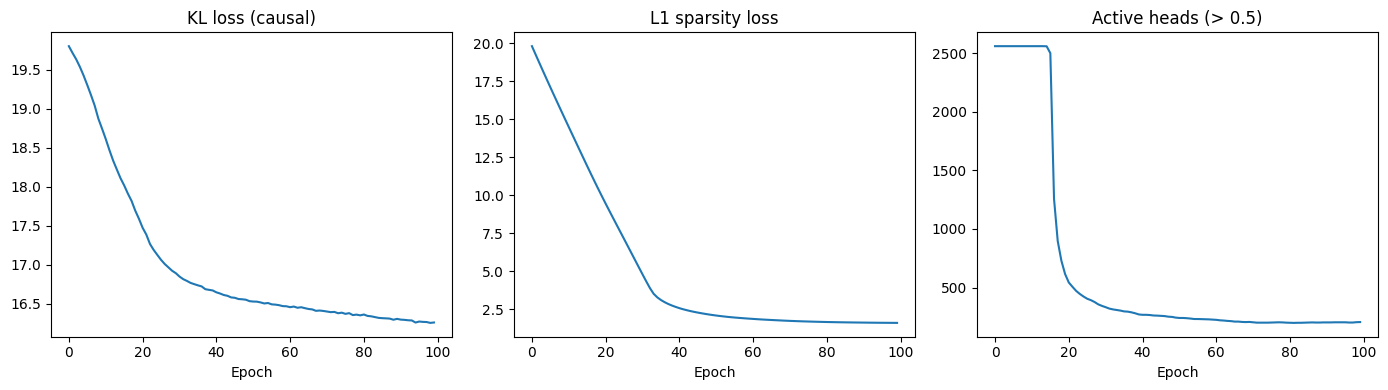

In [ ]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history.loss_causal)
axes[0].set_title("KL loss (causal)")
axes[0].set_xlabel("Epoch")

axes[1].plot(history.loss_sparse)
axes[1].set_title("L1 sparsity loss")
axes[1].set_xlabel("Epoch")

axes[2].plot(history.n_active)
axes[2].set_title("Active heads (> 0.5)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## Mask heatmap

2026-03-18 23:22:59 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7faed036ce90>


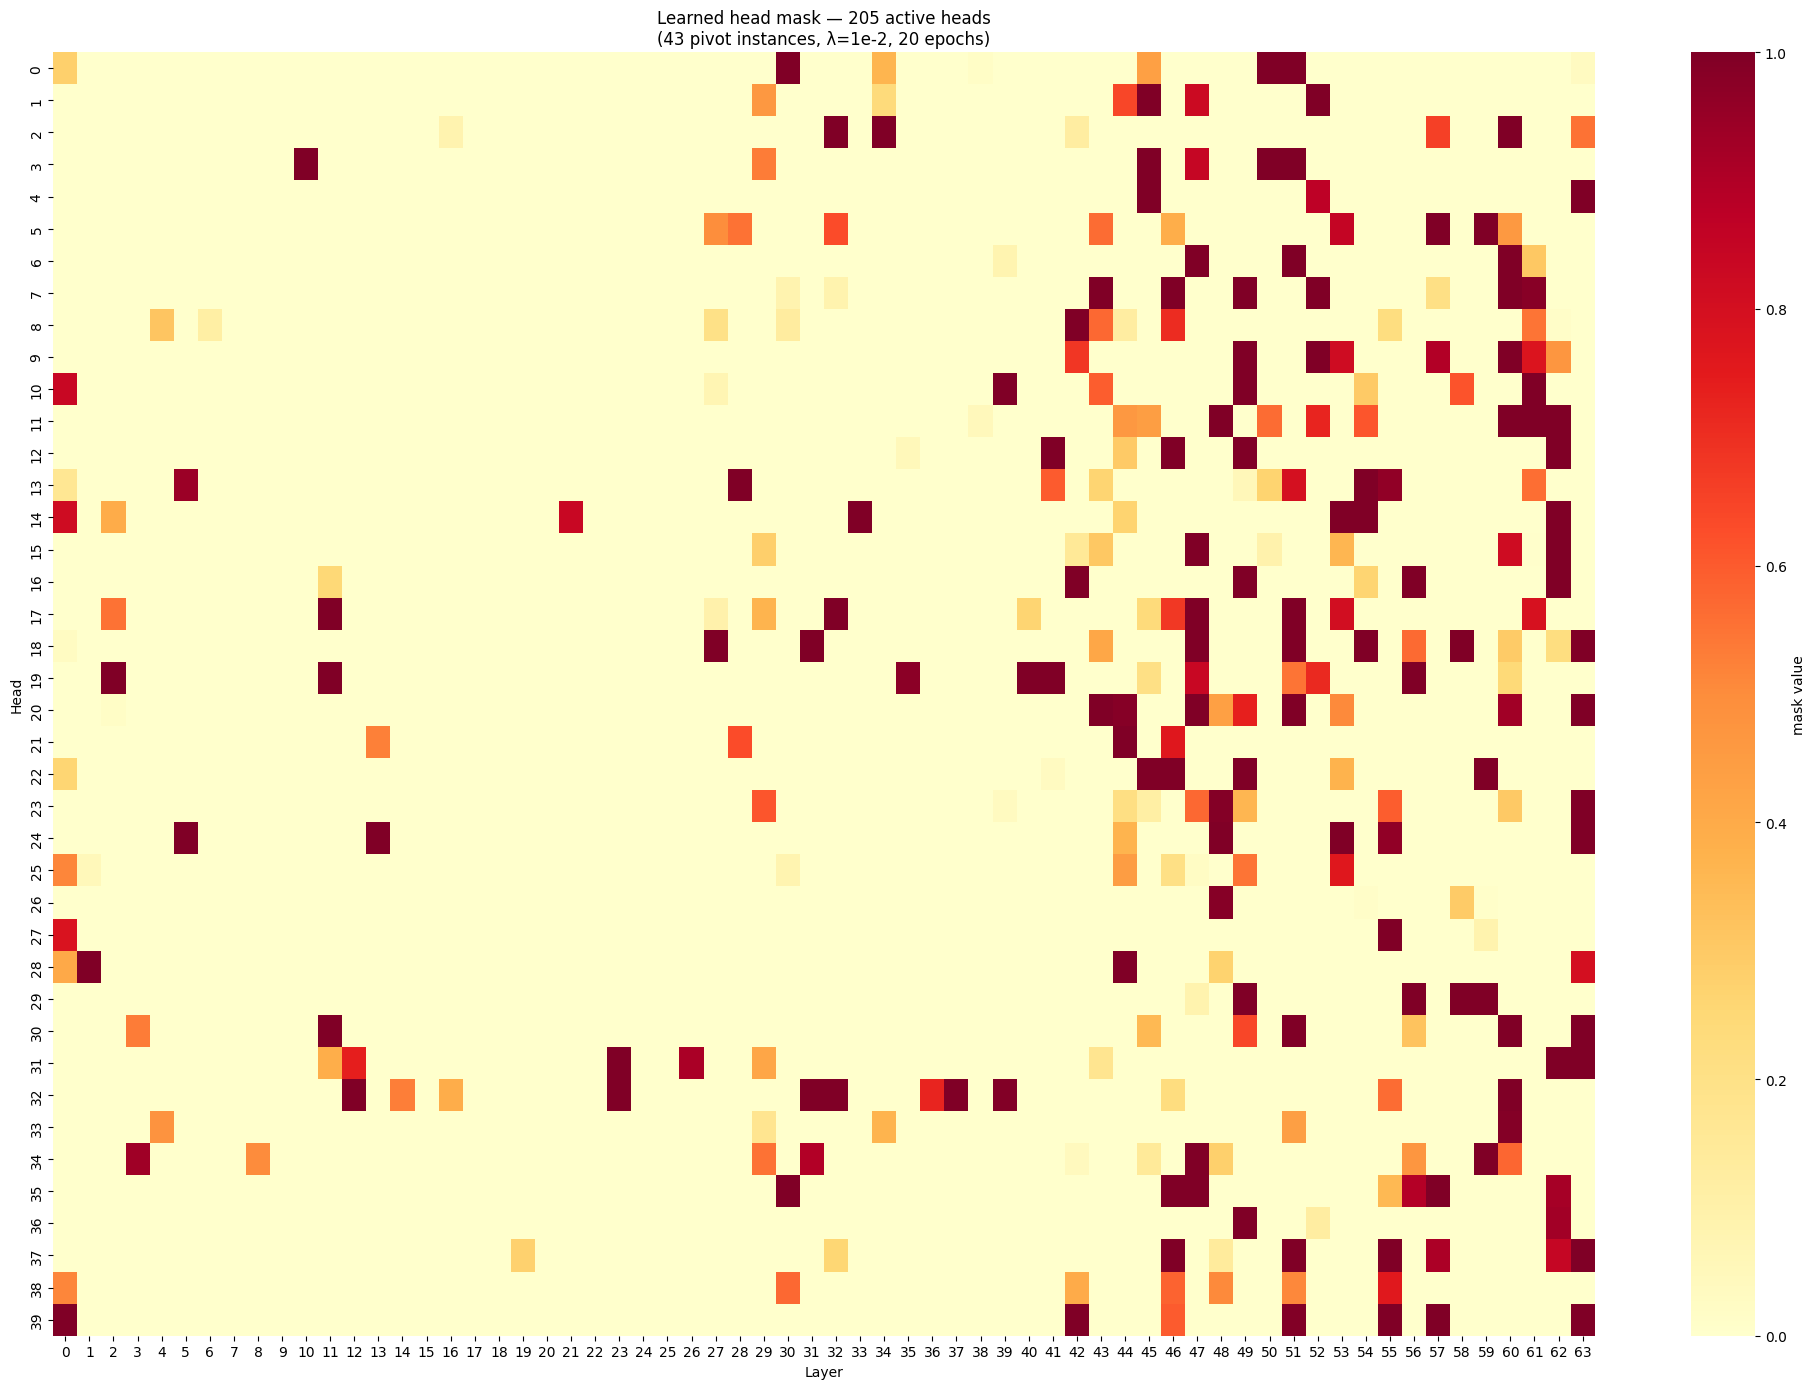


Top 10 heads by mask value:
  layer=59 head=22: 1.0000
  layer=1 head=28: 1.0000
  layer=49 head=10: 1.0000
  layer=45 head=22: 1.0000
  layer=48 head=24: 1.0000
  layer=30 head=0: 1.0000
  layer=54 head=14: 1.0000
  layer=31 head=32: 1.0000
  layer=54 head=13: 1.0000
  layer=59 head=5: 1.0000


In [ ]:
mask_vals = mask.values.detach().cpu().numpy()  # (n_layers_tested, n_heads)
import numpy as np

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    mask_vals.T, ax=ax, cmap="YlOrRd", vmin=0, vmax=1,
    xticklabels=[str(l) for l in LAYERS],
    yticklabels=range(n_heads),
    cbar_kws={"label": "mask value"},
)
ax.set_title(
    f"Learned head mask — {mask.n_active()} active heads\n"
    f"({len(pivot_instances)} pivot instances, λ=1e-2, 20 epochs)"
)
ax.set_xlabel("Layer")
ax.set_ylabel("Head")
plt.tight_layout()
plt.show()

print("\nTop 10 heads by mask value:")
flat = mask_vals.flatten()
for idx in np.argsort(flat)[::-1][:10]:
    li, h = divmod(int(idx), n_heads)
    print(f"  layer={LAYERS[li]} head={h}: {mask_vals[li, h]:.4f}")

## Sparsity sweep: λ vs. n_active vs. KL (Pareto frontier)

17:14:02 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 20 epochs | lr=0.01 λ=0.001
17:14:04 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.6388  sparse=1.5710  total=5.2098  n_active=1600
17:14:14 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1130  sparse=1.4074  total=3.5204  n_active=1574
17:14:27 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7670  sparse=1.2269  total=2.9938  n_active=1357
17:14:39 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5683  sparse=1.0787  total=2.6470  n_active=1185
17:14:51 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4358  sparse=0.9634  total=2.3993  n_active=1037
17:14:51 INFO src.goals.head_loc_attn — train_head_mask done: 1037 active heads → [(20, 3), (20, 4), (20, 5), (20, 11), (20, 15), (20, 18), (20, 25), (20, 27), (20, 28), (20, 33), (20, 34), (20, 39), (21, 1), (21, 4), (21, 6), (21, 8), (21, 9), (21, 11), (21, 13), (21, 15), (21, 18), (21, 26), (21, 27), (21, 31), (21,

  λ=1e-03: n_active=1037  KL=1.4358


17:14:53 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5949  sparse=7.7937  total=11.3886  n_active=1600
17:15:03 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0779  sparse=6.3495  total=8.4274  n_active=1507
17:15:14 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7208  sparse=4.5194  total=6.2402  n_active=933
17:15:26 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5331  sparse=3.2795  total=4.8126  n_active=665
17:15:38 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4172  sparse=2.5283  total=3.9455  n_active=506
17:15:38 INFO src.goals.head_loc_attn — train_head_mask done: 506 active heads → [(21, 32), (22, 29), (23, 6), (23, 23), (23, 26), (23, 31), (23, 35), (25, 38), (26, 9), (26, 27), (26, 31), (27, 8), (27, 10), (27, 17), (27, 18), (27, 19), (27, 21), (27, 23), (28, 4), (28, 5), (28, 12), (28, 13), (28, 17), (28, 21), (28, 23), (28, 24), (28, 25), (29, 1), (29, 2), (29, 4), (29, 17), (29, 18), (29, 19), (29, 22), (29, 23), (29, 31), (29, 39), (30, 0),

  λ=5e-03: n_active= 506  KL=1.4172


17:15:40 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5640  sparse=15.5110  total=19.0750  n_active=1600
17:15:49 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0515  sparse=11.7952  total=13.8468  n_active=1445
17:16:01 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7356  sparse=7.0230  total=8.7586  n_active=647
17:16:13 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5843  sparse=4.2879  total=5.8722  n_active=388
17:16:24 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4716  sparse=2.9599  total=4.4315  n_active=265
17:16:24 INFO src.goals.head_loc_attn — train_head_mask done: 265 active heads → [(23, 6), (27, 10), (27, 17), (27, 18), (28, 5), (28, 13), (29, 1), (29, 18), (29, 19), (29, 23), (30, 0), (30, 8), (30, 23), (30, 25), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 31), (31, 32), (31, 34), (32, 1), (32, 3), (32, 8), (32, 13), (32, 25), (32, 26), (32, 32), (32, 33), (33, 26), (33, 30), (33, 34), (34, 3), (34, 4), (34, 22), (34, 25

  λ=1e-02: n_active= 265  KL=1.4716


17:16:27 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:16:36 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:16:48 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:17:00 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:17:13 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:17:13 INFO src.goals.head_loc_attn — train_head_mask done: 134 active heads → [(27, 10), (29, 1), (29, 18), (30, 8), (30, 23), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 32), (31, 34), (32, 3), (33, 34), (34, 22), (34, 25), (35, 13), (35, 39), (38, 0), (38, 7), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (39, 34), (40, 3), (40, 8), (40, 11), (40, 13), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (42, 11), (43, 5)

  λ=2e-02: n_active= 134  KL=1.6196


17:17:15 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5004  sparse=76.7545  total=80.2549  n_active=1600
17:17:25 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.3505  sparse=49.4677  total=51.8182  n_active=1125
17:17:37 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=2.0425  sparse=15.5258  total=17.5683  n_active=139
17:17:52 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=2.0015  sparse=5.2949  total=7.2964  n_active=79
17:18:04 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.9817  sparse=3.4552  total=5.4369  n_active=64
17:18:04 INFO src.goals.head_loc_attn — train_head_mask done: 64 active heads → [(30, 8), (30, 35), (31, 18), (31, 32), (38, 0), (39, 8), (39, 9), (39, 31), (39, 32), (43, 15), (44, 21), (45, 1), (45, 3), (45, 17), (45, 18), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 39), (47, 8), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16),

  λ=5e-02: n_active=  64  KL=1.9817


17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansMandaic-Regular.ttf', name='Noto Sans Mandaic', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/freefont/FreeMonoBoldOblique.ttf', name='FreeMono', style='oblique', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/tlwg/TlwgTypewriter-Oblique.otf', name='Tlwg Typewriter', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/ipafont-mincho/ipamp.ttf', name='IPAPMincho', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matpl

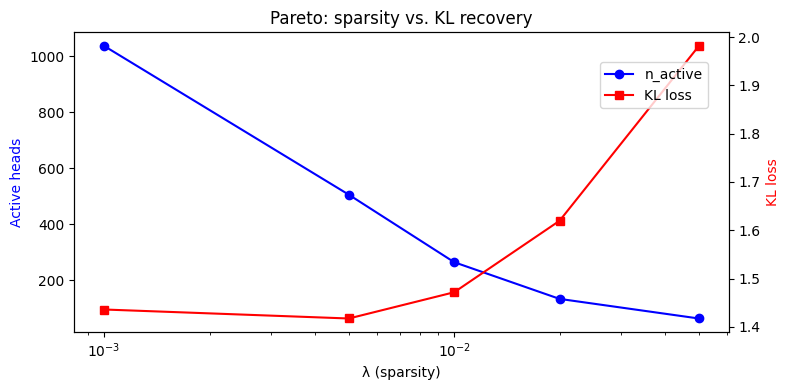

In [ ]:
# lambdas = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
lambdas = [1, 5, 10, 20, 50, 75, 100]
pareto = []

for lam in lambdas:
    m, h = train_head_mask(mt, pivot_caches, layers=LAYERS, n_epochs=20, lr=1e-2, lambda_sparse=lam)
    pareto.append((lam, m.n_active(), h.loss_causal[-1]))
    print(f"  λ={lam:.0e}: n_active={m.n_active():4d}  KL={h.loss_causal[-1]:.4f}")

lams, n_acts, kls = zip(*pareto)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.semilogx(lams, n_acts, "b-o", label="n_active")
ax2.semilogx(lams, kls, "r-s", label="KL loss")
ax1.set_xlabel("λ (sparsity)")
ax1.set_ylabel("Active heads", color="b")
ax2.set_ylabel("KL loss", color="r")
ax1.set_title("Pareto: sparsity vs. KL recovery")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()
plt.show()

---
## Load saved mask (from `train_head_mask.py`)

Use this section when loading a mask trained by the script rather than training inline above.

In [7]:
import os
import torch
from src.goals.head_loc_attn import HeadMask

MASK_PATH = "../results/localization/Qwen2.5-Coder-32B-Instruct/checkpoints/checkpoint_epoch_0050.pt"

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])

selected_heads = mask.selected_heads(LAYERS)
print(f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)")
print(f"  Active heads (mask > 0.5): {len(selected_heads)}")
print(f"  Selected heads: {selected_heads}")

Loaded checkpoint from ../results/localization/Qwen2.5-Coder-32B-Instruct/checkpoints/checkpoint_epoch_0050.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.5): 160
  Selected heads: [(0, 14), (23, 31), (23, 32), (28, 13), (29, 1), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (30, 38), (31, 18), (31, 19), (31, 32), (31, 34), (32, 3), (32, 13), (33, 34), (34, 8), (34, 30), (34, 33), (35, 13), (35, 39), (37, 15), (37, 33), (38, 0), (38, 2), (38, 26), (38, 38), (39, 9), (39, 31), (39, 32), (39, 33), (39, 34), (40, 2), (40, 8), (40, 9), (40, 11), (40, 14), (40, 19), (40, 30), (40, 32), (40, 34), (40, 39), (41, 6), (41, 9), (41, 12), (41, 13), (41, 21), (42, 5), (42, 14), (42, 39), (43, 5), (43, 8), (43, 13), (43, 15), (43, 24), (43, 30), (44, 1), (44, 7), (44, 12), (44, 14), (44, 21), (44, 22), (44, 38), (45, 1), (45, 4), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 23), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 17

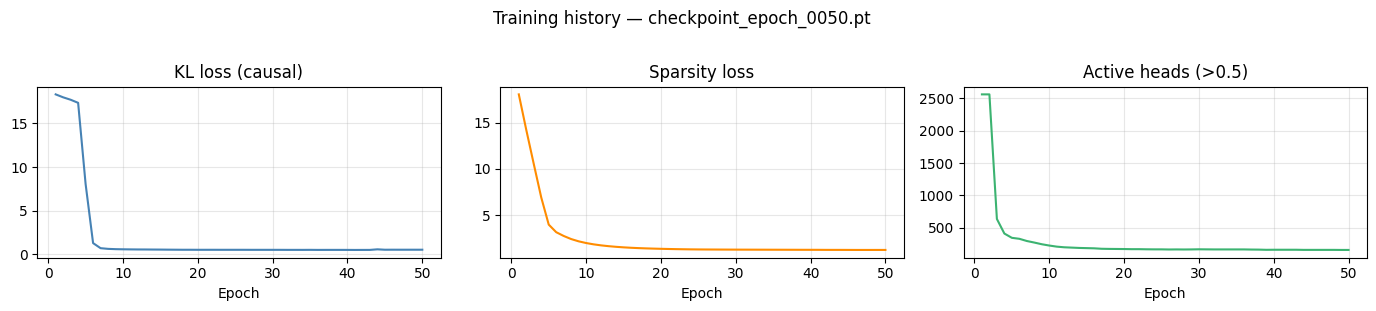

In [9]:
# Training curves from the checkpoint
from matplotlib import pyplot as plt
import numpy as np

plt.rcdefaults()

h = ckpt["history"]
xs = np.arange(1, len(h["loss_total"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(xs, h["loss_causal"],  color="steelblue");  axes[0].set_title("KL loss (causal)")
axes[1].plot(xs, h["loss_sparse"],  color="darkorange"); axes[1].set_title("Sparsity loss")
axes[2].plot(xs, h["n_active"],     color="mediumseagreen"); axes[2].set_title("Active heads (>0.5)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
plt.suptitle(f"Training history — {os.path.basename(MASK_PATH)}", y=1.02)
plt.tight_layout()
plt.show()

In [10]:
len(selected_heads)

160

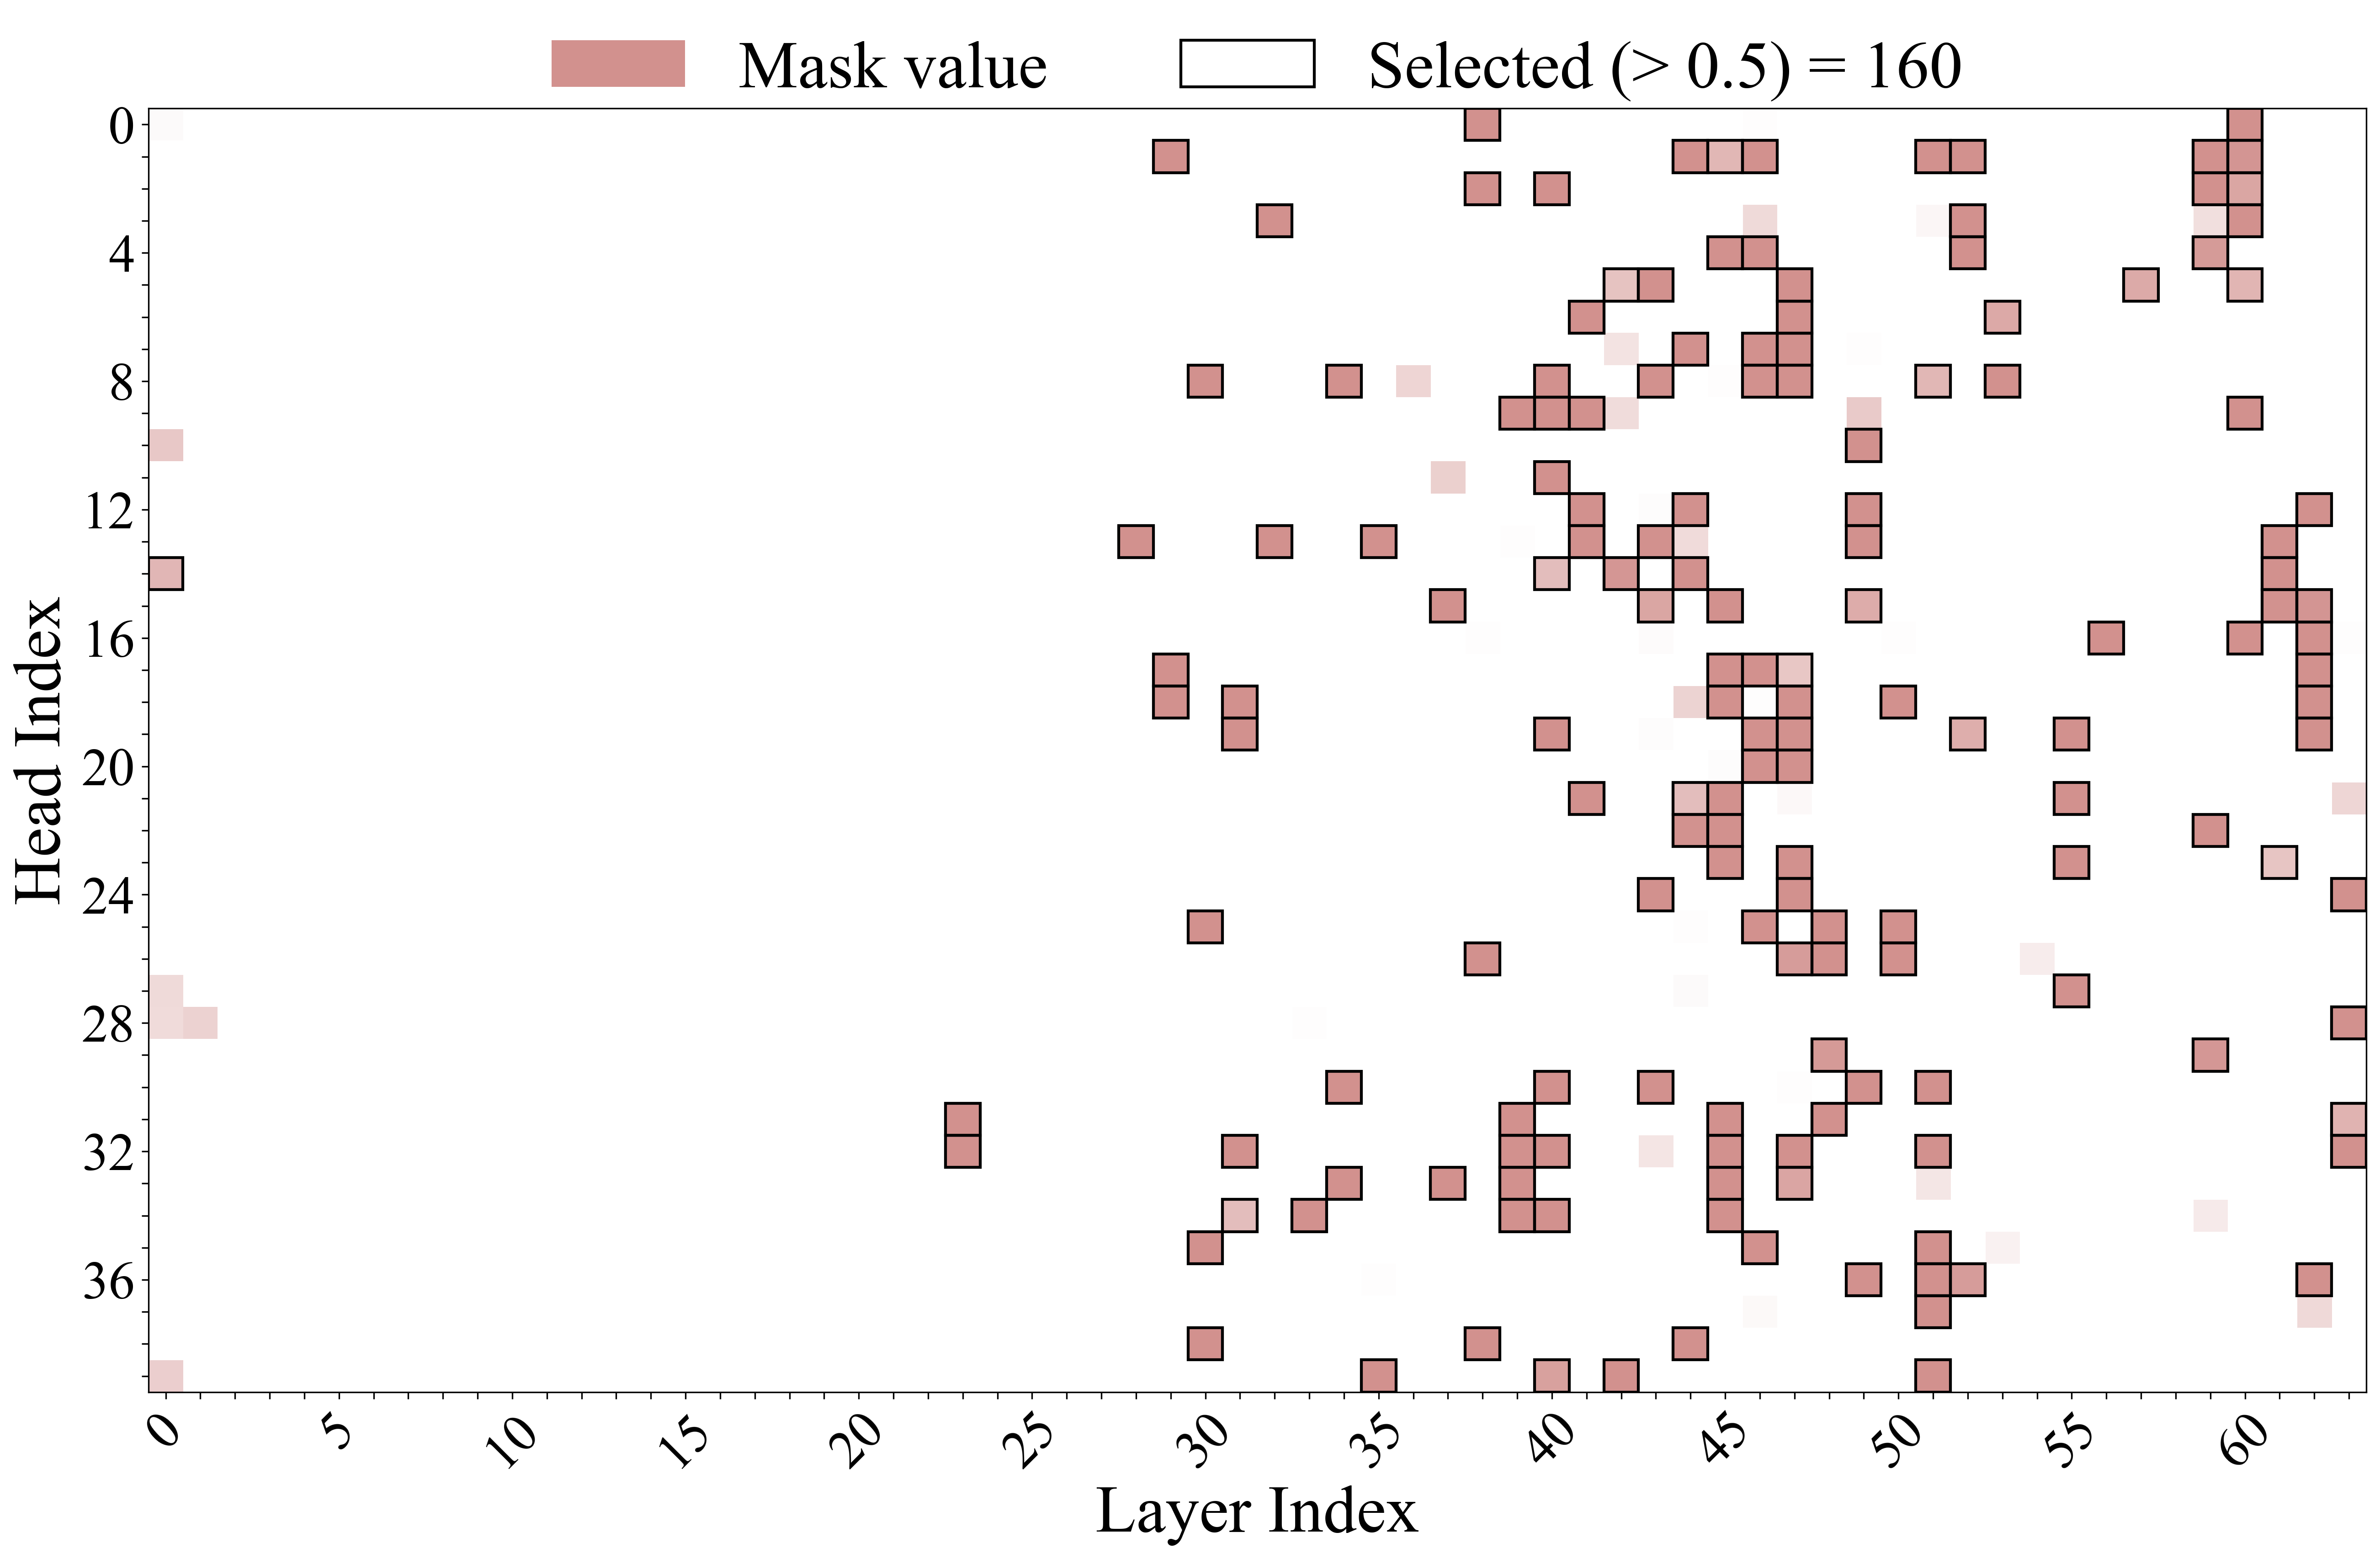

In [12]:
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import pyplot as plt
from matplotlib import patches

plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 28
MEDIUM_SIZE = 35
BIGGER_SIZE = 40

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

def get_ticks(ticks, skip=5, offset=0):
    ret = []
    for i in ticks:
        actual_layer = i + offset
        if actual_layer % skip == 0:
            ret.append(str(actual_layer))
        else:
            ret.append("")
    return ret

_n_heads = mt.config.num_attention_heads
_n_layer = mt.n_layer

# Build continuous mask matrix: shape (n_heads, n_layer)
# Layers outside the optimized range stay 0.
function_mask = torch.zeros((_n_heads, _n_layer), dtype=torch.float32)
for i, layer_idx in enumerate(LAYERS):
    function_mask[:, layer_idx] = mask.values[i].detach().cpu()

# Create figure and axis
fig, ax = plt.subplots(figsize=(18, 12))

colors = ["white", "#BF625E"]
cmap = LinearSegmentedColormap.from_list("white_orange", colors, N=100)

ax.imshow(
    function_mask.numpy(),
    cmap=cmap,
    aspect="auto",
    vmin=0,
    vmax=1,
    alpha=0.7,
)

# Black border around selected heads (mask value > 0.5)
for layer_idx, head_idx in selected_heads:
    rect = patches.Rectangle(
        (layer_idx - 0.5, head_idx - 0.5),
        1, 1,
        linewidth=1.5,
        edgecolor="black",
        facecolor="none",
    )
    ax.add_patch(rect)

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(
    ticks=range(_n_layer),
    labels=get_ticks(range(_n_layer)),
    rotation=45,
)
plt.yticks(
    ticks=range(_n_heads),
    labels=get_ticks(range(_n_heads), skip=4),
)

legend_elements = [
    mpatches.Patch(facecolor="#BF625E", alpha=0.7, label="Mask value"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1.5, label=f"Selected (> 0.5) = {len(selected_heads)}"),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=2,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()


---
## Attention pattern visualization for selected heads

`get_attention_matrices` runs one forward pass with `output_attentions=True` and returns
an `AttentionInformation` object: `.attention_matrices` is `(n_layers, n_heads, seq, seq)`.

`visualize_attn_matrix` uses **circuitsvis** to show which source tokens the last query
token (or any `q_index`) attends to for a given `(layer, head)`.

The cells below visualize:
1. Each head in `selected_heads` on the **source** (C++) prompt.
2. Each head on the **destination** (Python) prompt — shows what changes after patching.

In [13]:
from src.attention import get_attention_matrices, visualize_attn_matrix
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick a pivot instance to inspect — change IDX to explore others
# VIS_IDX = 0
# pair_v, pi_v = pivot_instances[VIS_IDX]

pair_v, pi_v = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
][0]  # Just pick the first matching instance

src_prompt_v = build_cpp_prompt(
    mt, ds.get_sample(pair_v.source_predicate), include_docstring=True
)
dest_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.destination_predicate),
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)
targ_prompt_v = build_python_prompt(
    mt,
    ds.get_sample(pair_v.source_predicate),  # source_predicate = Python target
    pivot_prefix=pi_v.pivot_prefix,
    include_docstring=True,
)

print(f"Pair: {pair_v.destination_predicate!r} ← {pair_v.source_predicate!r}")
print(
    f"Pivot prefix: {pi_v.pivot_prefix!r}  |  target token: {pi_v.target_top_token!r}"
)
print(f"\nActive heads ({len(selected_heads)}): {selected_heads}")

# One forward pass each — output_attentions=True (eager mode required)
attn_src = get_attention_matrices(src_prompt_v, mt, value_weighted=True)
attn_dest = get_attention_matrices(dest_prompt_v, mt, value_weighted=True)
attn_targ = get_attention_matrices(targ_prompt_v, mt, value_weighted=True)

Pair: 'is_lower' ← 'is_palindrome'
Pivot prefix: 's == s'  |  target token: '[::-'

Active heads (160): [(0, 14), (23, 31), (23, 32), (28, 13), (29, 1), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (30, 38), (31, 18), (31, 19), (31, 32), (31, 34), (32, 3), (32, 13), (33, 34), (34, 8), (34, 30), (34, 33), (35, 13), (35, 39), (37, 15), (37, 33), (38, 0), (38, 2), (38, 26), (38, 38), (39, 9), (39, 31), (39, 32), (39, 33), (39, 34), (40, 2), (40, 8), (40, 9), (40, 11), (40, 14), (40, 19), (40, 30), (40, 32), (40, 34), (40, 39), (41, 6), (41, 9), (41, 12), (41, 13), (41, 21), (42, 5), (42, 14), (42, 39), (43, 5), (43, 8), (43, 13), (43, 15), (43, 24), (43, 30), (44, 1), (44, 7), (44, 12), (44, 14), (44, 21), (44, 22), (44, 38), (45, 1), (45, 4), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 23), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 17), (46, 19), (46, 20), (46, 25), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 17), (47, 18), (47

In [14]:
top_heads = sorted(
    selected_heads, key=lambda x: mask.values[LAYERS.index(x[0]), x[1]], reverse=True
)
for layer_idx, head_idx in top_heads:
    mask_val = mask.values[LAYERS.index(layer_idx), head_idx].item()
    print(f"Layer {layer_idx} Head {head_idx} (mask={mask_val:.4f}):")


Layer 23 Head 31 (mask=1.0000):
Layer 23 Head 32 (mask=1.0000):
Layer 29 Head 1 (mask=1.0000):
Layer 29 Head 17 (mask=1.0000):
Layer 29 Head 18 (mask=1.0000):
Layer 30 Head 8 (mask=1.0000):
Layer 30 Head 35 (mask=1.0000):
Layer 30 Head 38 (mask=1.0000):
Layer 31 Head 18 (mask=1.0000):
Layer 31 Head 19 (mask=1.0000):
Layer 31 Head 32 (mask=1.0000):
Layer 32 Head 3 (mask=1.0000):
Layer 32 Head 13 (mask=1.0000):
Layer 34 Head 8 (mask=1.0000):
Layer 34 Head 30 (mask=1.0000):
Layer 34 Head 33 (mask=1.0000):
Layer 35 Head 13 (mask=1.0000):
Layer 35 Head 39 (mask=1.0000):
Layer 37 Head 15 (mask=1.0000):
Layer 38 Head 0 (mask=1.0000):
Layer 38 Head 2 (mask=1.0000):
Layer 38 Head 26 (mask=1.0000):
Layer 38 Head 38 (mask=1.0000):
Layer 39 Head 9 (mask=1.0000):
Layer 39 Head 31 (mask=1.0000):
Layer 39 Head 32 (mask=1.0000):
Layer 39 Head 33 (mask=1.0000):
Layer 39 Head 34 (mask=1.0000):
Layer 40 Head 8 (mask=1.0000):
Layer 40 Head 9 (mask=1.0000):
Layer 40 Head 11 (mask=1.0000):
Layer 40 Head 19 

In [15]:
# Visualize each selected head on the C++ source prompt (last-token query)
# What does this head attend to when the model processes the C++ goal signal?

print("=" * 80)
print("ATTENTION PATTERNS — C++ source prompt (last token query)")
print("=" * 80)

for layer, head in top_heads[:5]:
    mask_val = mask.values[LAYERS.index(layer), head].item()
    print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
    mat = attn_src.get_attn_matrix(layer, head)
    visualize_attn_matrix(mat, attn_src.tokenized_prompt, q_index=-1, start_from=0)

ATTENTION PATTERNS — C++ source prompt (last token query)

── Layer  23  Head  31  (mask=1.000) ──



── Layer  23  Head  32  (mask=1.000) ──



── Layer  29  Head   1  (mask=1.000) ──



── Layer  29  Head  17  (mask=1.000) ──



── Layer  29  Head  18  (mask=1.000) ──


In [18]:
aggregated_src_attn = []
for layer, head in top_heads[:20]:
    aggregated_src_attn.append(torch.Tensor(attn_src.get_attn_matrix(layer, head)))

aggregated_src_attn = torch.stack(
    aggregated_src_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_src_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(mean_attn, attn_src.tokenized_prompt, q_index=-1, start_from=0)

In [16]:
# Same heads on the Python destination prompt — what does the dest model attend to?
# Comparing src vs dest attention for the same head reveals what the patch is changing.

print("=" * 80)
print("ATTENTION PATTERNS — Python destination prompt (last token query)")
print("=" * 80)

for layer, head in top_heads[:5]:
    mask_val = mask.values[LAYERS.index(layer), head].item()
    print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
    mat = attn_dest.get_attn_matrix(layer, head)
    visualize_attn_matrix(mat, attn_dest.tokenized_prompt, q_index=-1, start_from=0)

ATTENTION PATTERNS — Python destination prompt (last token query)

── Layer  23  Head  31  (mask=1.000) ──



── Layer  23  Head  32  (mask=1.000) ──



── Layer  29  Head   1  (mask=1.000) ──



── Layer  29  Head  17  (mask=1.000) ──



── Layer  29  Head  18  (mask=1.000) ──


In [17]:
aggregated_dest_attn = []
for layer, head in top_heads[:20]:
    aggregated_dest_attn.append(torch.Tensor(attn_dest.get_attn_matrix(layer, head)))

aggregated_dest_attn = torch.stack(
    aggregated_dest_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_dest_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_dest.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

In [18]:
# Visualize each selected head on the C++ source prompt (last-token query)
# What does this head attend to when the model processes the C++ goal signal?

print("=" * 80)
print("ATTENTION PATTERNS — python target prompt (last token query)")
print("=" * 80)

for layer, head in top_heads[:5]:
    mask_val = mask.values[LAYERS.index(layer), head].item()
    print(f"\n── Layer {layer:3d}  Head {head:3d}  (mask={mask_val:.3f}) ──")
    mat = attn_targ.get_attn_matrix(layer, head)
    visualize_attn_matrix(mat, attn_targ.tokenized_prompt, q_index=-1, start_from=0)

ATTENTION PATTERNS — python target prompt (last token query)

── Layer  23  Head  31  (mask=1.000) ──



── Layer  23  Head  32  (mask=1.000) ──



── Layer  29  Head   1  (mask=1.000) ──



── Layer  29  Head  17  (mask=1.000) ──



── Layer  29  Head  18  (mask=1.000) ──


In [19]:
aggregated_target_attn = []
for layer, head in top_heads[:20]:
    aggregated_target_attn.append(torch.Tensor(attn_targ.get_attn_matrix(layer, head)))

aggregated_target_attn = torch.stack(
    aggregated_target_attn, dim=0
)  # (n_selected_heads, seq_len, seq_len)
mean_attn = aggregated_target_attn.mean(dim=0)  # (seq_len, seq_len)
visualize_attn_matrix(
    mean_attn, attn_targ.tokenized_prompt, q_index=-1, start_from=0
)  # (n_selected_heads, seq_len, seq_len)

In [20]:
mask.n_active()

160

## Qualitative Analysis

In [27]:
selected_instances = [
    (predicate_pair, pivot_idx)
    for predicate_pair, pivot_idx in pivot_instances
    if predicate_pair.source_predicate == "is_palindrome"
    and pivot_idx.pivot_prefix.strip().endswith("s == s")
]
len(selected_instances)

10

In [28]:
import torch
from rich.console import Console
from rich.table import Table

from src.goals.head_loc_attn import (
    HeadMask, forward_with_masked_patch,
    get_o_proj_inputs_batch, precompute_per_head_deltas_batch,
)
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt
from src.tokens import prepare_input
from src.trace import get_score

# ── Binary mask: 1.0 at selected heads, 0.0 everywhere else ──────────────────
_n_lt = len(LAYERS)
_n_h  = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in selected_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total")

METRIC          = "logit"   # "logit" or "prob"
MAX_NEW_TOKENS  = 20
PATCH_ALL_TOKENS = True   # True  → patch every generated token
                            # False → patch only the pivot (first token), then greedy

_STOP_IDS = {mt.tokenizer.eos_token_id} | set(mt.tokenizer.encode("\n", add_special_tokens=False))


def _greedy_continue(mt, input_ids, attention_mask, max_new_tokens):
    """Plain greedy generation — no patching."""
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            out = mt._model(input_ids=input_ids, attention_mask=attention_mask)
            next_tok = int(out.logits[0, -1].argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [attention_mask, torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)], dim=1
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def _patched_generate(mt, dest_inputs, per_head_deltas, mask, layers, max_new_tokens):
    """Greedy generation with head patching applied at every token position."""
    input_ids     = dest_inputs["input_ids"].clone()
    attention_mask = dest_inputs["attention_mask"].clone()
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
            # forward_with_masked_patch always patches the last token position,
            # so as the sequence grows the intervention follows the generation frontier.
            logits = forward_with_masked_patch(mt, inputs, per_head_deltas, mask, layers)
            next_tok = int(logits.argmax())
            generated.append(next_tok)
            if next_tok in _STOP_IDS:
                break
            input_ids = torch.cat(
                [input_ids, torch.tensor([[next_tok]], device=input_ids.device)], dim=1
            )
            attention_mask = torch.cat(
                [attention_mask, torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)], dim=1
            )
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


Binary mask: 160 active heads / 2560 total


In [52]:
import logging
from src.goals.head_loc_module import _top5_str
from src.utils.metrics import recall, AggregateMetric
from src.goals.head_loc_pivot import (
    build_cpp_prompt,
    build_python_prompt,
    build_java_prompt,
    build_haskell_prompt,
    build_prolog_prompt,
    build_rust_prompt,
)

logger = logging.getLogger(__name__)
console = Console(width=130, highlight=False)

K_RECALL = 5  # recall@k to report

# Accumulate across instances
_dest_preds_all = []
_patched_preds_all = []
_targets_all = []
_ie_all = []

for idx, (pair, pi) in enumerate(selected_instances[:1]):
    src_sample = ds.get_sample(pair.source_predicate)
    dest_sample = ds.get_sample(pair.destination_predicate)
    targ_sample = ds.get_sample(pair.source_predicate)

    # src_prompt  = build_cpp_prompt(mt, src_sample, include_docstring=True)
    # src_prompt = build_java_prompt(mt, src_sample, include_docstring=True)
    src_prompt = build_rust_prompt(mt, src_sample, include_docstring=True)
    dest_prompt = build_python_prompt(
        mt, dest_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
    )
    targ_prompt = build_python_prompt(
        mt, targ_sample, pivot_prefix=pi.pivot_prefix, include_docstring=True
    )

    logger.debug(
        f"\n{'=' * 80}\nInstance {idx}: {pair.destination_predicate} ← {pair.source_predicate}  prefix={pi.pivot_prefix!r}"
    )
    logger.debug(f"[src prompt]\n{src_prompt}")
    logger.debug(f"[dest prompt]\n{dest_prompt}")
    logger.debug(f"[targ prompt]\n{targ_prompt}")

    target_tok_id = mt.tokenizer.encode(pi.target_top_token, add_special_tokens=False)[
        0
    ]

    dest_inputs = prepare_input([dest_prompt], tokenizer=mt)
    targ_inputs = prepare_input([targ_prompt], tokenizer=mt)

    # ── Per-head deltas ───────────────────────────────────────────────────────
    combined_o = get_o_proj_inputs_batch(mt, [src_prompt, dest_prompt], LAYERS)
    src_o = {l: combined_o[l][:1] for l in LAYERS}
    dest_o = {l: combined_o[l][1:] for l in LAYERS}
    per_head_deltas = precompute_per_head_deltas_batch(
        mt, src_o, dest_o, LAYERS
    )  # (1, L, H, E)

    # ── Three forward passes ──────────────────────────────────────────────────
    with torch.no_grad():
        logits_dest = mt._model(**dest_inputs).logits[0, -1]
        logits_targ = mt._model(**targ_inputs).logits[0, -1]
        logits_patched = forward_with_masked_patch(
            mt, dict(dest_inputs), per_head_deltas[0], binary_mask, LAYERS
        )

    score_dest = get_score(logits_dest, target_tok_id, metric=METRIC)
    score_targ = get_score(logits_targ, target_tok_id, metric=METRIC)
    score_patched = get_score(logits_patched, target_tok_id, metric=METRIC)
    ie = (score_patched - score_dest) / (score_targ - score_dest + 1e-8)

    logger.debug(
        f"[dest]    top5: {_top5_str(mt, logits_dest, METRIC)}  target({pi.target_top_token!r})={score_dest:.4f}"
    )
    logger.debug(
        f"[targ]    top5: {_top5_str(mt, logits_targ, METRIC)}  target({pi.target_top_token!r})={score_targ:.4f}"
    )
    logger.debug(
        f"[patched] top5: {_top5_str(mt, logits_patched, METRIC)}  target({pi.target_top_token!r})={score_patched:.4f}  IE={ie:.3f}"
    )

    # ── Accumulate ───────────────────────────────────────────────────────────
    def _topk_toks(logits, k):
        return [mt.tokenizer.decode([i]) for i in logits.topk(k).indices.tolist()]

    _dest_preds_all.append(_topk_toks(logits_dest, K_RECALL))
    _patched_preds_all.append(_topk_toks(logits_patched, K_RECALL))
    _targets_all.append(pi.target_top_token)
    _ie_all.append(ie)

    # ── Generation ───────────────────────────────────────────────────────────
    src_gen = _greedy_continue(
        mt,
        prepare_input([src_prompt], tokenizer=mt)["input_ids"],
        prepare_input([src_prompt], tokenizer=mt)["attention_mask"],
        MAX_NEW_TOKENS,
    )
    dest_gen = _greedy_continue(
        mt,
        dest_inputs["input_ids"].clone(),
        dest_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )
    targ_gen = _greedy_continue(
        mt,
        targ_inputs["input_ids"].clone(),
        targ_inputs["attention_mask"].clone(),
        MAX_NEW_TOKENS,
    )

    if PATCH_ALL_TOKENS:
        # Patch at every generated token position (same delta injected each step).
        patched_gen = _patched_generate(
            mt,
            dict(dest_inputs),
            per_head_deltas[0],
            binary_mask,
            LAYERS,
            MAX_NEW_TOKENS,
        )
    else:
        # Patch only the pivot (first token), then continue greedily.
        patched_first_tok = int(logits_patched.argmax())
        _dev = dest_inputs["input_ids"].device
        _ids_p = torch.cat(
            [
                dest_inputs["input_ids"],
                torch.tensor([[patched_first_tok]], device=_dev),
            ],
            dim=1,
        )
        _msk_p = torch.cat(
            [
                dest_inputs["attention_mask"],
                torch.ones(
                    (1, 1), dtype=dest_inputs["attention_mask"].dtype, device=_dev
                ),
            ],
            dim=1,
        )
        patched_gen = mt.tokenizer.decode([patched_first_tok]) + _greedy_continue(
            mt, _ids_p, _msk_p, MAX_NEW_TOKENS - 1
        )

    # ── Per-instance table ────────────────────────────────────────────────────
    patch_mode = "patch-all" if PATCH_ALL_TOKENS else "patch-pivot"
    pfx = f"return {pi.pivot_prefix}" if pi.pivot_prefix else "return"
    console.print(
        f"\n[bold cyan]Instance {idx}[/bold cyan]  "
        f"[bright_green]{pair.destination_predicate}[/bright_green] ← [bright_red]{pair.source_predicate}[/bright_red]  "
        f"prefix={pi.pivot_prefix!r}  target_tok=[bright_magenta][bold]{pi.target_top_token!r}[/bold][/bright_magenta]  [{patch_mode}]"
    )
    table = Table(highlight=False, show_header=True, pad_edge=False, box=None)
    table.add_column("run", style="bright_cyan", width=12)
    table.add_column(METRIC, style="salmon1", width=8, justify="right")
    table.add_column("IE", style="bright_magenta", width=7, justify="right")
    table.add_column("generation", width=85)
    table.add_row("src (C++)", "—", "—", f"{src_gen}")
    table.add_row(
        "dest (base)",
        f"{score_dest:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{dest_gen}",
    )
    table.add_row(
        "targ (sky)",
        f"{score_targ:.4f}",
        "—",
        f"[bright_yellow]{pfx}[/bright_yellow]{targ_gen}",
    )
    table.add_row(
        "patched",
        f"{score_patched:.4f}",
        f"{ie:.3f}",
        f"[bright_yellow]{pfx}[/bright_yellow]{patched_gen}",
    )
    console.print(table)

# ── Aggregate summary ─────────────────────────────────────────────────────────
recall_dest = recall(_dest_preds_all, _targets_all)
recall_patched = recall(_patched_preds_all, _targets_all)
ie_agg = AggregateMetric.aggregate(_ie_all)

summary = Table(
    title=f"Summary  (N={len(_targets_all)})", highlight=False, show_header=True
)
summary.add_column("run", style="cyan")
summary.add_column("IE  mean±se", style="salmon1", justify="right")
for k in range(1, K_RECALL + 1):
    summary.add_column(f"recall@{k}", style="bright_yellow", justify="right")
summary.add_row(
    "dest (baseline)",
    "—",
    *[f"{recall_dest[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
summary.add_row(
    "patched",
    str(ie_agg),
    *[f"{recall_patched[k - 1]:.3f}" for k in range(1, K_RECALL + 1)],
)
console.print()
console.print(summary)


2026-03-20 16:35:14 __main__ DEBUG    
Instance 0: is_lower ← is_palindrome  prefix='s == s'
2026-03-20 16:35:14 __main__ DEBUG    [src prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Rust function below.<|im_end|>
<|im_start|>assistant
<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return 
2026-03-20 16:35:14 __main__ DEBUG    [dest prompt]
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_lower(s: str) -> bool:
    """Return True if all alphabetic characters in s are low

2026-03-20 16:35:18 __main__ DEBUG    [dest]    top5: [ "'.lower'" (36.25), "'.toLowerCase'" (21.25), "' lower'" (20.62), "'lower'" (19.50), "'_lower'" (19.38) ]  target('[::-')=13.5625
2026-03-20 16:35:18 __main__ DEBUG    [targ]    top5: [ "'[::-'" (33.25), "'['" (19.50), "'[-'" (19.12), "'[:'" (18.62), "'.reverse'" (18.00) ]  target('[::-')=33.2500
2026-03-20 16:35:18 __main__ DEBUG    [patched] top5: [ "'[::-'" (27.62), "'.lower'" (20.88), "'['" (17.75), "'[:'" (16.88), "'.reverse'" (15.12) ]  target('[::-')=27.6250  IE=0.714


Instance 0  is_lower ← is_palindrome  prefix='s == s'  target_tok='[::-'

run              logit       IE  generation                                                                           
src (C++)            —        —   s.chars().eq(s.chars().rev());                                                      
                                 }                                                                                    
                                                                                                                      
                                 fn main() {                                                                          
                                     let test_str = "                                                                 
dest (base)    13.5625        —  return s == s.lower()                                                                
                                 </code>                                                                              
                                                                                                                      
                                 This function checks if all alphabetic characters in the string `s` are              
targ (sky)     33.2500        —  return s == s[::-1]                                                                  
                                 </code>                                                                              
                                                                                                                      
                                 This function `is_palindrome` takes a string `s` as                                  
patched        27.6250    0.714  return s == s[::-1] and s == s.lower()                                               
                                 </code>                                                                              
                                                                                                                      
                                 The function provided above is incorrect as it

                                     Summary  (N=1)                                     
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━┓
┃ run             ┃ IE  mean±se ┃ recall@1 ┃ recall@2 ┃ recall@3 ┃ recall@4 ┃ recall@5 ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━┩
│ dest (baseline) │           — │    0.000 │    0.000 │    0.000 │    0.000 │    0.000 │
│ patched         │ 0.71 ± 0.00 │    1.000 │    1.000 │    1.000 │    1.000 │    1.000 │
└─────────────────┴─────────────┴──────────┴──────────┴──────────┴──────────┴──────────┘

In [49]:
from src.functional import generate_with_patch

prompt = src_prompt
gen = generate_with_patch(
    mt=mt,
    inputs=prompt,
    n_gen_per_prompt=5,
    max_new_tokens=32,
    do_sample=True,
    remove_prefix=True,
)

In [50]:
rich_print(f"[white]{prompt}[white][salmon1]{gen[3]}[/salmon1]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make 
sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Rust function below.<|im_end|>
<|im_start|>assistant
<code>
/// Return True if s reads the same forwards and backwards.
fn is_palindrome(s: &str) -> bool {
    return  s.chars().eq(s.chars().rev());
}
</code>

This function `is_palindrome` takes a string slice `&str` as an argument and

---
## Augmented training

`augment_pivot_caches` applies **one random augmentation per instance** (1× expansion) and returns a fresh set of lazy `PivotCache` objects (no precomputed deltas).

Augmentation type is sampled with weights:

| Type | Weight | What changes |
|------|--------|--------------|
| `source_lang` | 55% | `src_prompt` swapped to Java / Rust / Haskell / Prolog; `log_p_target` reused |
| `variable_rename` | 35% | variable renamed via `_VAR_VOCAB`; `src_prompt`, `dest_prompt`, `pivot_prefix`, `log_p_target` updated; falls back to `source_lang` if var not in vocab |
| `toggle_type_hints` | 10% | Python type annotations stripped from `def` line; `src_prompt`, `dest_prompt`, `log_p_target` updated |

**Requirements:** `pivot_caches` must have `per_head_deltas=None` (i.e., `cache_pivot_data` called with `precompute_deltas=False`).  
When used in training (`--augment`), `augment_pivot_caches` is called at the start of every epoch, so the model sees a different surface form each time.

In [ ]:
from src.goals.head_loc_attn import augment_pivot_caches

# Requires pivot_caches with lazy deltas (precompute_deltas=False).
# If not already computed:
#   pivot_caches = cache_pivot_data(mt, selected_pivot_instances, ds, layers=LAYERS, precompute_deltas=False)

AUG_INSTANCES = 10  # test on a small slice

aug_caches = augment_pivot_caches(
    mt,
    pivot_caches=pivot_caches[:AUG_INSTANCES],
    pivot_instances=selected_pivot_instances[:AUG_INSTANCES],
    ds=ds,
    cache_batch_size=8,
)

print(f"Input caches   : {AUG_INSTANCES}")
print(f"Augmented caches: {len(aug_caches)}  (should equal {AUG_INSTANCES} — 1× expansion)")
print(f"All lazy        : {all(c.per_head_deltas is None for c in aug_caches)}")

In [14]:
# Inspect a few augmented prompts side-by-side with their originals
from rich.console import Console
from rich.table import Table

_console = Console(width=140, highlight=False)

SHOW = 10   # how many to display

for i in range(min(SHOW, len(aug_caches))):
    orig = pivot_caches[i // 2]   # rough correspondence (2 aug per orig on average)
    aug  = aug_caches[i]

    table = Table(highlight=False, show_header=True, pad_edge=False, box=None)
    table.add_column("", style="cyan", width=10)
    table.add_column("dest prompt (last 300 chars)", width=120)
    table.add_row("original", orig.dest_prompt[-300:])
    table.add_row("augmented", aug.dest_prompt[-300:])
    _console.print(f"\n[bold]Augmented cache {i}[/bold]")
    _console.print(table)


Augmented cache 0

            dest prompt (last 300 chars)                                                                                            
original    icient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes  
            inside the <code> </code> tags.<|im_end|>                                                                               
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s: str) -> bool:                                                                                           
                return s == s                                                                                                       
augmented    proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all   
            codes inside the <code> </code> tags.<|im_end|>                                                                         
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s) -> bool:                                                                                                
                return s == s

Augmented cache 1

            dest prompt (last 300 chars)                                                                                            
original    icient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes  
            inside the <code> </code> tags.<|im_end|>                                                                               
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s: str) -> bool:                                                                                           
                return s == s                                                                                                       
augmented    programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the
            <code> </code> tags.<|im_end|>                                                                                          
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(text: str) -> bool:                                                                                        
                return text == text

Augmented cache 2

            dest prompt (last 300 chars)                                                                                            
original    t in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside
            the <code> </code> tags.<|im_end|>                                                                                      
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s: str) -> bool:                                                                                           
                return bool(s == s                                                                                                  
augmented   hen completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code>
            tags.<|im_end|>                                                                                                         
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(input_str: str) -> bool:                                                                                   
                return input_str == input_str

... (10 outputs left out)

Augmented cache 8

            dest prompt (last 300 chars)                                                                                            
original     programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the
            <code> </code> tags.<|im_end|>                                                                                          
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s: str) -> bool:                                                                                           
                return False or s == s                                                                                              
augmented   ent in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes     
            inside the <code> </code> tags.<|im_end|>                                                                               
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s) -> bool:                                                                                                
                return not not s == s

Augmented cache 9

            dest prompt (last 300 chars)                                                                                            
original     programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the
            <code> </code> tags.<|im_end|>                                                                                          
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(s: str) -> bool:                                                                                           
                return False or s == s                                                                                              
augmented   ming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> 
            </code> tags.<|im_end|>                                                                                                 
            <|im_start|>user                                                                                                        
            Complete the Python function below.<|im_end|>                                                                           
            <|im_start|>assistant                                                                                                   
            <code>                                                                                                                  
            def is_lower(text: str) -> bool:                                                                                        
                return not not text == text